In [1]:
import pandas as pd
from pathlib import Path

In [2]:
DATA_PATH = Path("../../data/raw/BIOPRO_L.xpt")

dataset = pd.read_sas(DATA_PATH, format="xport")

In [3]:
dataset.head()

,SEQN,WTPH2YR,LBXSATSI,LBXSAL,LBDSALSI,LBXSAPSI,LBXSASSI,LBXSC3SI,LBXSBU,LBDSBUSI,...,LBXSCA,LBDSCASI,LBXSCH,LBDSCHSI,LBXSTP,LBDSTPSI,LBXSTR,LBDSTRSI,LBXSUA,LBDSUASI
0,130378.0,56042.129410,39.0,4.3,43.0,91.0,25.0,24.0,11.0,3.9,...,9.6,2.4,266.0,6.89,7.5,75.0,153.0,1.73,5.1,303.3
1,130379.0,37435.705647,17.0,3.9,39.0,64.0,20.0,25.0,24.0,8.6,...,9.4,2.4,217.0,5.62,7.3,73.0,88.0,0.99,8.5,505.6
2,130380.0,85328.844519,13.0,3.7,37.0,78.0,15.0,25.0,10.0,3.6,...,9.4,2.4,183.0,4.74,7.6,76.0,375.0,4.24,4.4,261.7
3,130386.0,44526.214135,34.0,4.3,43.0,54.0,20.0,21.0,17.0,6.1,...,9.5,2.4,185.0,4.79,6.9,69.0,140.0,1.58,6.0,356.9
4,130387.0,22746.296353,12.0,3.7,37.0,116.0,13.0,24.0,15.0,5.4,...,9.3,2.3,203.0,5.26,6.7,67.0,111.0,1.25,6.2,368.8


In [4]:
dataset.shape

(7199, 42)

In [5]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 7199 entries, 0 to 7198
Data columns (total 42 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SEQN      7199 non-null   float64
 1   WTPH2YR   7199 non-null   float64
 2   LBXSATSI  6321 non-null   float64
 3   LBXSAL    6366 non-null   float64
 4   LBDSALSI  6366 non-null   float64
 5   LBXSAPSI  6327 non-null   float64
 6   LBXSASSI  6308 non-null   float64
 7   LBXSC3SI  6325 non-null   float64
 8   LBXSBU    6326 non-null   float64
 9   LBDSBUSI  6326 non-null   float64
 10  LBXSCLSI  6329 non-null   float64
 11  LBXSCK    6321 non-null   float64
 12  LBXSCR    6326 non-null   float64
 13  LBDSCRSI  6326 non-null   float64
 14  LBXSGB    6364 non-null   float64
 15  LBDSGBSI  6364 non-null   float64
 16  LBXSGL    6357 non-null   float64
 17  LBDSGLSI  6357 non-null   float64
 18  LBXSGTSI  6327 non-null   float64
 19  LBDSGTLC  6327 non-null   float64
 20  LBXSIR    6364 non-null   float64
 21  LB

In [6]:
missing_values = dataset.isna().sum().to_frame(name="missing_count")

missing_values["missing_percentage"] = (
    missing_values["missing_count"] / len(dataset) * 100
).round(2)

missing_values.sort_values(
    by="missing_percentage",
    ascending=False
)

,missing_count,missing_percentage
LBXSLDSI,2459,34.16
LBDSTBSI,1006,13.97
LBXSKSI,918,12.75
LBXSASSI,891,12.38
LBXSATSI,878,12.20
LBXSCK,878,12.20
LBXSOSSI,877,12.18
LBDSPHSI,877,12.18
LBXSPH,877,12.18
LBXMAGN,875,12.15


In [7]:
print("Unique IDs:", dataset["SEQN"].nunique())
print("Missing IDs:", dataset["SEQN"].isna().sum())
print("Duplicate IDs:", dataset["SEQN"].duplicated().sum())

Unique IDs: 7199
Missing IDs: 0
Duplicate IDs: 0


In [8]:
dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
SEQN,7199.0,136328.407696,3442.024649,1.303780e+05,1.333210e+05,1.363660e+05,1.392860e+05,142310.000000
WTPH2YR,7199.0,38893.262398,30918.802145,5.397605e-79,1.878176e+04,3.103185e+04,4.962340e+04,241728.857241
LBXSATSI,6321.0,21.065338,16.056092,3.000000e+00,1.200000e+01,1.700000e+01,2.500000e+01,350.000000
LBXSAL,6366.0,4.099246,0.355161,2.200000e+00,3.900000e+00,4.100000e+00,4.300000e+00,5.500000
LBDSALSI,6366.0,40.992460,3.551609,2.200000e+01,3.900000e+01,4.100000e+01,4.300000e+01,55.000000
LBXSAPSI,6327.0,94.272641,51.711316,2.000000e+01,6.800000e+01,8.300000e+01,1.030000e+02,731.000000
LBXSASSI,6308.0,22.301046,14.291143,6.000000e+00,1.600000e+01,2.000000e+01,2.400000e+01,518.000000
LBXSC3SI,6325.0,24.449012,2.411849,1.500000e+01,2.300000e+01,2.400000e+01,2.600000e+01,37.000000
LBXSBU,6326.0,14.659817,5.754035,4.000000e+00,1.100000e+01,1.400000e+01,1.700000e+01,74.000000
LBDSBUSI,6326.0,5.235694,2.054251,1.400000e+00,3.900000e+00,5.000000e+00,6.100000e+00,26.400000


In [9]:
columns_to_inspect = [
    "WTPH2YR",
    "LBDSGTLC",
    "LBDSTBLC"
]

for column_name in columns_to_inspect:
    print(f"\n--- {column_name} ---")
    print(dataset[column_name].value_counts(dropna=False).head(10))


--- WTPH2YR ---
WTPH2YR
5.397605e-79    449
1.387989e+04      3
1.542516e+04      3
1.364805e+04      3
2.284125e+04      3
2.669873e+04      3
1.970007e+04      3
6.852681e+04      3
2.461621e+04      3
1.234443e+04      2
Name: count, dtype: int64

--- LBDSGTLC ---
LBDSGTLC
5.397605e-79    6326
NaN              872
1.000000e+00       1
Name: count, dtype: int64

--- LBDSTBLC ---
LBDSTBLC
5.397605e-79    6193
NaN              874
1.000000e+00     132
Name: count, dtype: int64


In [10]:
for column_name in ["WTPH2YR", "LBDSGTLC", "LBDSTBLC"]:
    print(f"\n--- {column_name} ---")
    print("Minimum value:", dataset[column_name].min())
    print("Maximum value:", dataset[column_name].max())
    print("Unique values:", dataset[column_name].nunique())
    print("Number of zeros:", (dataset[column_name] == 0).sum())
    print("Number of tiny values:", (dataset[column_name] < 1e-70).sum())


--- WTPH2YR ---
Minimum value: 5.397605346934028e-79
Maximum value: 241728.8572411242
Unique values: 6600
Number of zeros: 0
Number of tiny values: 449

--- LBDSGTLC ---
Minimum value: 5.397605346934028e-79
Maximum value: 1.0
Unique values: 2
Number of zeros: 0
Number of tiny values: 6326

--- LBDSTBLC ---
Minimum value: 5.397605346934028e-79
Maximum value: 1.0
Unique values: 2
Number of zeros: 0
Number of tiny values: 6193


In [11]:
SAS_ZERO_ARTIFACT = 5.397605346934028e-79

dataset = dataset.replace(SAS_ZERO_ARTIFACT, 0.0)

In [12]:
for column_name in ["WTPH2YR", "LBDSGTLC", "LBDSTBLC"]:
    print(f"\n--- {column_name} ---")
    print("Minimum value:", dataset[column_name].min())
    print("Number of zeros:", (dataset[column_name] == 0).sum())


--- WTPH2YR ---
Minimum value: 0.0
Number of zeros: 449

--- LBDSGTLC ---
Minimum value: 0.0
Number of zeros: 6326

--- LBDSTBLC ---
Minimum value: 0.0
Number of zeros: 6193


### Handling SAS reading artifacts

During the exploration, the value
5.397605346934028e-79 was identified in three variables.

This value is an artifact of converting numbers in the
SAS XPORT Pandas reader, which represents certain
zeros as extremely small numbers.

The value was replaced with 0.0, preserving the original
meaning of the variables.

- WTPH2YR: a zero sample weight indicates no blood sample.
- LBDSGTLC and LBDSTBLC: codes related to the detection limit.

Source: NHANES documentation and Pandas technical documentation.

In [13]:
for i, column_name in enumerate(dataset.columns, start=1):
    print(f"{i:02d}. {column_name}")

01. SEQN
02. WTPH2YR
03. LBXSATSI
04. LBXSAL
05. LBDSALSI
06. LBXSAPSI
07. LBXSASSI
08. LBXSC3SI
09. LBXSBU
10. LBDSBUSI
11. LBXSCLSI
12. LBXSCK
13. LBXSCR
14. LBDSCRSI
15. LBXSGB
16. LBDSGBSI
17. LBXSGL
18. LBDSGLSI
19. LBXSGTSI
20. LBDSGTLC
21. LBXSIR
22. LBDSIRSI
23. LBXSLDSI
24. LBXMAGN
25. LBXSOSSI
26. LBXSPH
27. LBDSPHSI
28. LBXSKSI
29. LBXSNASI
30. LBXSTB
31. LBDSTBSI
32. LBDSTBLC
33. LBXSCA
34. LBDSCASI
35. LBXSCH
36. LBDSCHSI
37. LBXSTP
38. LBDSTPSI
39. LBXSTR
40. LBDSTRSI
41. LBXSUA
42. LBDSUASI


In [14]:
selected_features = [
    "LBXSATSI",
    "LBDSALSI",
    "LBXSAPSI",
    "LBXSASSI",
    "LBXSC3SI",
    "LBDSBUSI",
    "LBXSCLSI",
    "LBDSCRSI",
    "LBXSGTSI",
    "LBDSIRSI",
    "LBXMAGN",
    "LBDSPHSI",
    "LBXSKSI",
    "LBXSNASI",
    "LBDSTBSI",
    "LBDSCASI",
    "LBDSTPSI",
    "LBDSUASI"
]

In [15]:
ml_dataset = dataset[selected_features].copy()

missing_values = pd.DataFrame({
    "missing_count": ml_dataset.isna().sum(),
    "missing_percentage": (
        ml_dataset.isna().mean() * 100
    ).round(2)
})

missing_values.sort_values(
    "missing_percentage",
    ascending=False
)

,missing_count,missing_percentage
LBDSTBSI,1006,13.97
LBXSKSI,918,12.75
LBXSASSI,891,12.38
LBXSATSI,878,12.20
LBDSPHSI,877,12.18
LBXMAGN,875,12.15
LBXSC3SI,874,12.14
LBDSBUSI,873,12.13
LBDSCRSI,873,12.13
LBXSAPSI,872,12.11


In [16]:
missing_per_person = ml_dataset.isna().sum(axis=1)

missing_per_person.value_counts().sort_index()

0     6090
1      214
2       13
3        7
5        2
7        2
11      13
12      25
18     833
Name: count, dtype: int64

In [17]:
no_exams = ml_dataset.isna().all(axis=1)

zero_sample_weight = dataset["WTPH2YR"] == 0

pd.crosstab(
    no_exams,
    zero_sample_weight,
    rownames=["No exams"],
    colnames=["Zero sample weight"]
)

Zero sample weight,False,True
No exams,,
False,6366,0
True,384,449


In [18]:
demographic_data = pd.read_sas(
    "../../data/raw/DEMO_L.xpt",
    format="xport"
)

demographic_data[["SEQN", "RIDAGEYR"]].head()

,SEQN,RIDAGEYR
0,130378.0,43.0
1,130379.0,66.0
2,130380.0,44.0
3,130381.0,5.0
4,130382.0,2.0


In [19]:
missing_exams_analysis = pd.DataFrame({
    "SEQN": dataset["SEQN"].values,
    "no_exams": no_exams.values,
    "zero_sample_weight": zero_sample_weight.values
})

missing_exams_analysis = missing_exams_analysis.merge(
    demographic_data[["SEQN", "RIDAGEYR"]],
    on="SEQN",
    how="left",
    validate="one_to_one"
)

In [20]:
missing_exams_analysis.groupby("no_exams")["RIDAGEYR"].describe()

,count,mean,std,min,25%,50%,75%,max
no_exams,,,,,,,,
False,6366.0,48.590795,20.700934,12.0,31.0,52.0,66.0,80.0
True,833.0,41.649460,23.171851,12.0,18.0,39.0,64.0,80.0


In [21]:
missing_exams_analysis["age_group"] = pd.cut(
    missing_exams_analysis["RIDAGEYR"],
    bins=[11, 19, 39, 59, 80],
    labels=["12-19", "20-39", "40-59", "60-80"]
)

In [22]:
pd.crosstab(
    [
        missing_exams_analysis["age_group"],
        missing_exams_analysis["zero_sample_weight"]
    ],
    missing_exams_analysis["no_exams"],
    margins=True
)

no_exams                      False  True   All
age_group zero_sample_weight                   
12-19     False                 888    70   958
          True                    0   177   177
20-39     False                1383    74  1457
          True                    0   102   102
40-59     False                1589    88  1677
          True                    0    56    56
60-80     False                2506   152  2658
          True                    0   114   114
All                            6366   833  7199

In [23]:
missing_exams_analysis[
    (missing_exams_analysis["no_exams"]) &
    (~missing_exams_analysis["zero_sample_weight"])
]["age_group"].value_counts().sort_index()

age_group
12-19     70
20-39     74
40-59     88
60-80    152
Name: count, dtype: int64

In [24]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


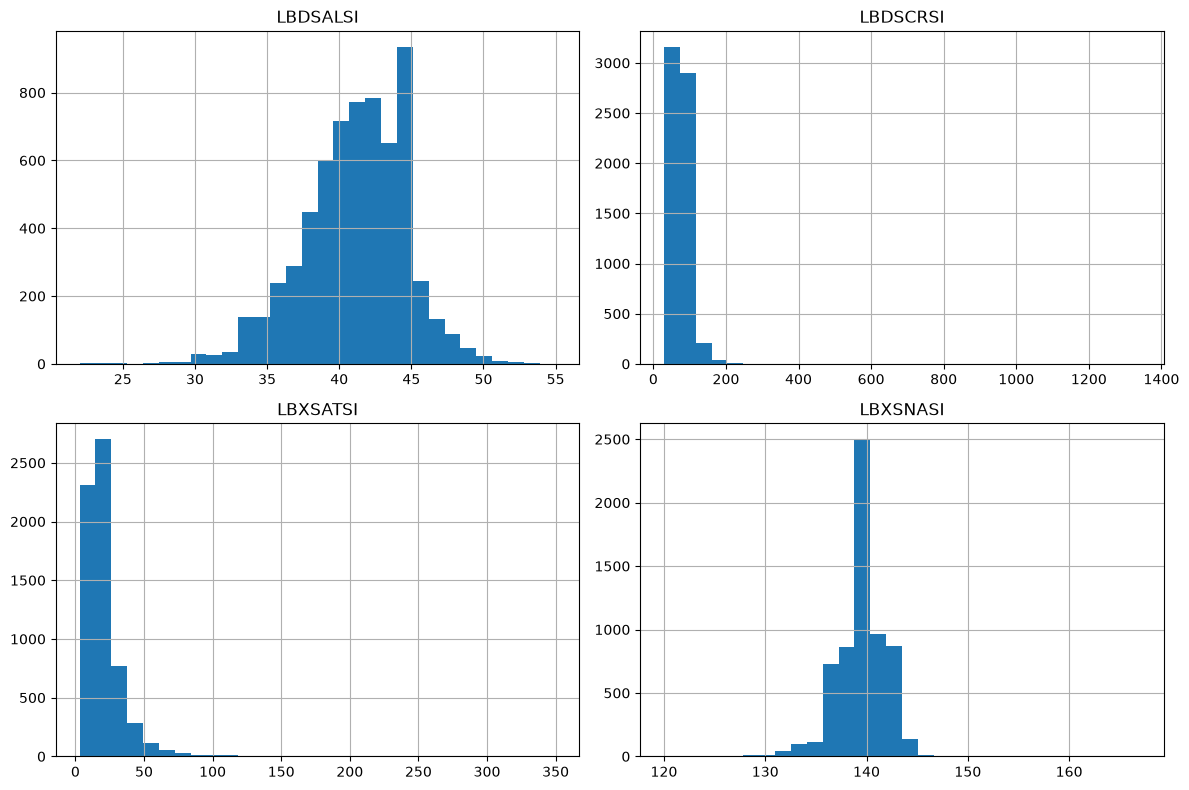

In [25]:
import matplotlib.pyplot as plt

variables = [
    "LBDSALSI",
    "LBDSCRSI",
    "LBXSATSI",
    "LBXSNASI"
]

ml_dataset[variables].hist(
    bins=30,
    figsize=(12, 8)
)

plt.tight_layout()
plt.show()

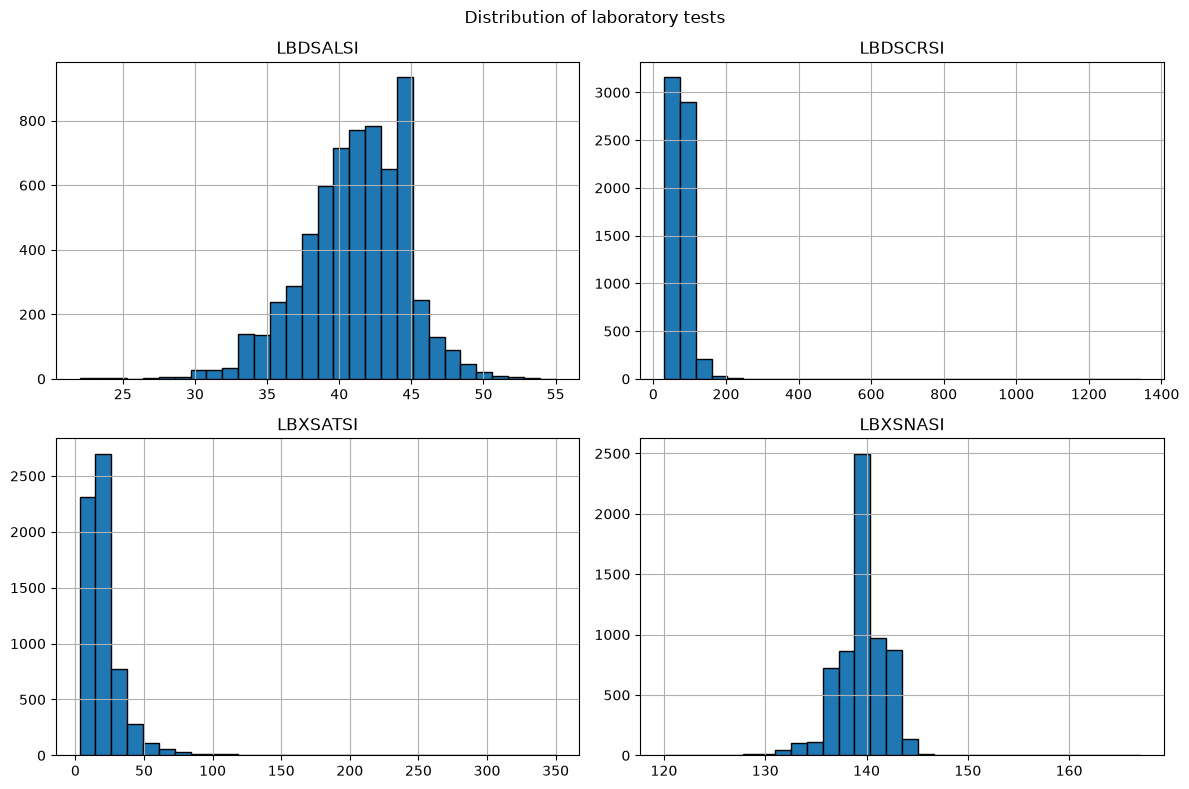

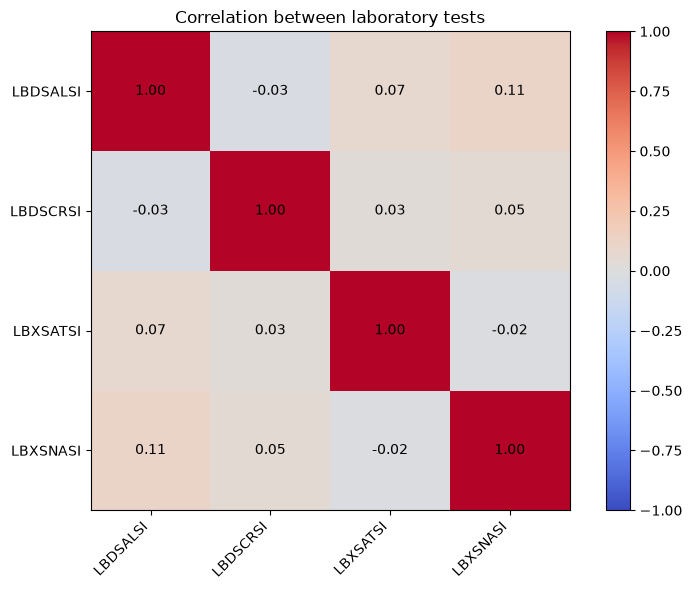

In [26]:
ml_dataset[variables].hist(
    bins=30,
    figsize=(12, 8),
    edgecolor="black"
)

plt.suptitle("Distribution of laboratory tests")
plt.tight_layout()
plt.show()

correlation = ml_dataset[variables].corr()

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(variables)))
ax.set_yticks(range(len(variables)))
ax.set_xticklabels(variables, rotation=45, ha="right")
ax.set_yticklabels(variables)
for row_index in range(len(variables)):
    for column_index in range(len(variables)):
        ax.text(
            column_index,
            row_index,
            f"{correlation.iloc[row_index, column_index]:.2f}",
            ha="center",
            va="center"
        )
fig.colorbar(image, ax=ax)
ax.set_title("Correlation between laboratory tests")
plt.tight_layout()
plt.show()

In [27]:
summary = ml_dataset.describe().T

summary["skewness"] = ml_dataset.skew()

summary["missing"] = ml_dataset.isna().sum()

summary = summary[
    [
        "count",
        "mean",
        "std",
        "min",
        "25%",
        "50%",
        "75%",
        "max",
        "skewness",
        "missing"
    ]
]

summary.round(2)


,count,mean,std,min,25%,50%,75%,max,skewness,missing
LBXSATSI,6321.0,21.07,16.06,3.00,12.00,17.00,25.00,350.00,5.49,878
LBDSALSI,6366.0,40.99,3.55,22.00,39.00,41.00,43.00,55.00,-0.42,833
LBXSAPSI,6327.0,94.27,51.71,20.00,68.00,83.00,103.00,731.00,4.00,872
LBXSASSI,6308.0,22.30,14.29,6.00,16.00,20.00,24.00,518.00,13.28,891
LBXSC3SI,6325.0,24.45,2.41,15.00,23.00,24.00,26.00,37.00,-0.00,874
LBDSBUSI,6326.0,5.24,2.05,1.40,3.90,5.00,6.10,26.40,2.34,873
LBXSCLSI,6329.0,101.42,2.92,82.00,100.00,102.00,103.00,133.00,-0.51,870
LBDSCRSI,6326.0,77.16,34.08,29.17,61.88,73.37,86.63,1341.03,15.61,873
LBXSGTSI,6327.0,28.08,44.08,2.00,13.00,18.00,29.00,1541.00,13.42,872
LBDSIRSI,6364.0,15.93,6.42,1.00,11.00,15.00,20.00,68.00,0.78,835


In [31]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

df_model = ml_dataset.dropna(how="all").copy()

X_train, X_test = train_test_split(
    df_model,
    test_size=0.20,
    random_state=42
)

imputer = SimpleImputer(strategy="median")
scaler = RobustScaler()

X_train_imputed = imputer.fit_transform(X_train)

X_test_imputed = imputer.transform(X_test)

X_train_scaled = scaler.fit_transform(X_train_imputed)

X_test_scaled = scaler.transform(X_test_imputed)

In [30]:
print("Original dataset:", ml_dataset.shape)
print("Dataset after removing empty rows:", df_model.shape)

print("\nTraining set:", X_train_scaled.shape)
print("Test set:", X_test_scaled.shape)

print("\nMissing values in training set:",
      pd.isna(X_train_scaled).sum())

print("Missing values in test set:",
      pd.isna(X_test_scaled).sum())


Original dataset: (7199, 18)
Dataset after removing empty rows: (6366, 18)

Training set: (5092, 18)
Test set: (1274, 18)

Missing values in training set: 0
Missing values in test set: 0


## Isolation Forest: unsupervised experiment

Isolation Forest builds many random decision trees. Observations that are isolated with fewer random splits receive a higher statistical anomaly score. It does not learn clinical categories and the score must not be interpreted as a diagnosis.

The random 80/20 split below is retained only to test whether the score distribution and the fraction selected for review are reasonably stable on unseen records. There are no ground-truth anomaly labels, so accuracy, precision, recall and ROC-AUC are intentionally not reported. Imputation, scaling, model fitting and threshold definition use training records only.

`anomaly_fraction=0.02` defines a review capacity: the 2% highest training scores are flagged. It is not a prevalence estimate. Missingness is retained as metadata to check whether flags are concentrated among incomplete panels.

In [33]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parents[1]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from ml.training.isolation_forest import (
    fit_isolation_forest,
    summarize_holdout,
)

experiment = fit_isolation_forest(
    X_train,
    anomaly_fraction=0.02,
    random_state=42,
    n_estimators=300,
)

train_scores = experiment.score(X_train)
holdout_scores = experiment.score(X_test)

print('Training records:', len(train_scores))
print('Holdout stability summary (not accuracy):')
for metric, value in summarize_holdout(experiment, X_test).items():
    print(f'{metric}: {value}')


Training records: 5092
Holdout stability summary (not accuracy):
records: 1274
flagged_records: 28
flagged_fraction: 0.02197802197802198
score_median: 0.40200702315008663
score_p95: 0.48597479134454213


In [34]:
# Check whether the statistical flags are associated with incomplete panels.
# This is a data-quality/sensitivity check, not a clinical conclusion.
missingness_sensitivity = (
    holdout_scores.groupby('missing_feature_count')
    .agg(
        records=('is_statistically_unusual', 'size'),
        flagged_fraction=('is_statistically_unusual', 'mean'),
        median_anomaly_score=('anomaly_score', 'median'),
    )
    .round(4)
)
missingness_sensitivity


,records,flagged_fraction,median_anomaly_score
missing_feature_count,,,
0,1218,0.0222,0.4021
1,41,0.0244,0.4030
2,4,0.0000,0.4355
7,1,0.0000,0.3882
11,3,0.0000,0.3857
12,7,0.0000,0.3682
